In [3]:
import polars as pl
from pathlib import Path

DATA_DIR = Path.cwd().parent / "data" / "data-processed"

df = pl.read_csv(str(DATA_DIR / "normalized_data.csv"))
df

datetime,global_active_power,global_reactive_power,voltage,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3,conjunto
str,f64,f64,f64,f64,f64,f64,f64,str
"""2006-12-16T17:24:00.000000""",2.841077,2.63937,-1.758257,2.979274,-0.184677,-0.059108,1.269299,"""train"""
"""2006-12-16T17:25:00.000000""",3.887646,2.79991,-2.119751,3.980298,-0.184677,-0.059108,1.150174,"""train"""
"""2006-12-16T17:26:00.000000""",3.900454,3.352882,-2.221328,3.980298,-0.184677,0.106805,1.269299,"""train"""
"""2006-12-16T17:27:00.000000""",3.913261,3.388557,-2.086888,3.980298,-0.184677,-0.059108,1.269299,"""train"""
"""2006-12-16T17:28:00.000000""",2.337918,3.620449,-1.507302,2.413478,-0.184677,-0.059108,1.269299,"""train"""
…,…,…,…,…,…,…,…,…
"""2010-11-26T20:58:00.000000""",-0.150429,-1.088731,-0.088215,-0.154367,-0.184677,-0.225022,-0.755821,"""test"""
"""2010-11-26T20:59:00.000000""",-0.152258,-1.088731,-0.216679,-0.154367,-0.184677,-0.225022,-0.755821,"""test"""
"""2010-11-26T21:00:00.000000""",-0.157747,-1.088731,-0.270455,-0.19789,-0.184677,-0.225022,-0.755821,"""test"""


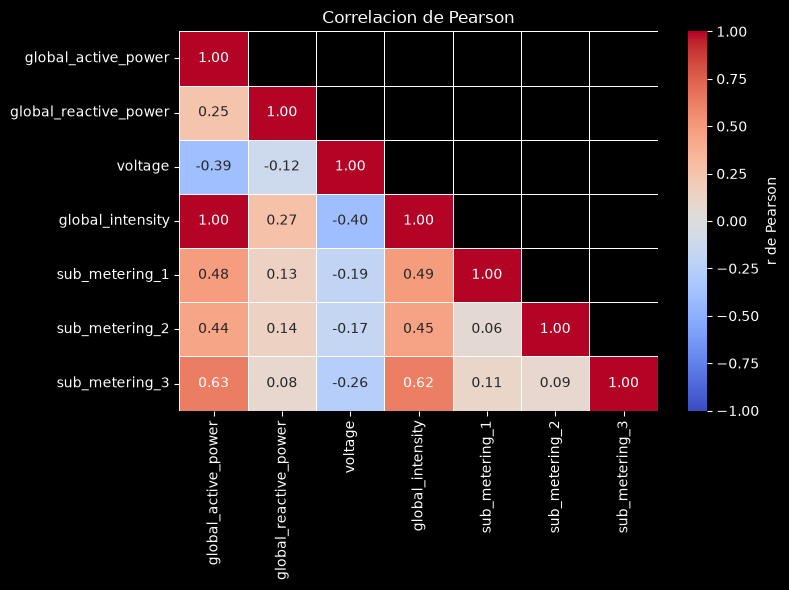

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from polars import selectors as sc

data = df.filter(pl.col("conjunto") == "train")
numeric = data.select(sc.numeric())
corr = numeric.corr()
corr_np = corr.to_numpy()
#para que no nos muestre toda la matriz 
mask = np.triu(np.ones_like(corr_np, dtype=bool), k=1)

cols = data.select(sc.numeric()).columns
plt.figure(figsize=(8, 6))
sns.heatmap(
    data=corr_np, 
    mask=mask,
    annot=True, 
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, 
    vmax=1, 
    linewidth=0.5, 
    xticklabels=cols, 
    yticklabels=cols,
    cbar_kws={"label": "r de Pearson"}
)
plt.title("Correlacion de Pearson")
plt.tight_layout()
plt.savefig(str(Path.cwd().parent / "graphs" / "heatmap_pearson.png"), dpi=500)
plt.show()


In [5]:
#creamos nuestra prueba de hipotesis de correlacion de pearson
from scipy import stats

res = stats.pearsonr(data["global_active_power"], data["global_intensity"])
print(res.statistic, res.pvalue)
print(res.confidence_interval(confidence_level=0.95))

0.9989541827033481 0.0
ConfidenceInterval(low=np.float64(0.9989509777200422), high=np.float64(0.9989573778998645))
